# BHARATH BUILDS
# DAY 16 — PRINCIPAL COMPONENT ANALYSIS (PCA)
### Dimensionality Reduction | Machine Learning in Kannada

---

## 1. LEARNING OBJECTIVES

By the end of this session, I aim to:

- Understand the concept of dimensionality reduction.
- Learn how Principal Component Analysis (PCA) works.
- Understand principal components and explained variance.
- Learn why feature scaling is necessary before PCA.
- Reduce the dimensionality of a dataset while preserving important information.
- Visualize high-dimensional data in two dimensions.
- Compare machine learning model performance before and after PCA.

---

## 2. THEORETICAL CONCEPTS COVERED

### Whiteboard Theory

1. Introduction to Dimensionality Reduction
2. Curse of Dimensionality
3. Principal Component Analysis (PCA)
4. Principal Components — PC1, PC2, and PC3
5. Variance and Explained Variance Ratio
6. Feature Scaling Before PCA
7. Projection of Data into Lower Dimensions
8. Choosing the Number of Principal Components
9. Advantages and Limitations of PCA
10. Real-World Applications of PCA

---

## 3. PRACTICAL CONCEPTS TO BE COVERED

### Google Colab Implementation

- Import the required Python libraries.
- Load the Wine Dataset.
- Identify the original number of features.
- Split the dataset into training and testing sets.
- Apply StandardScaler for feature scaling.
- Implement PCA with two principal components.
- Calculate explained variance ratio.
- Visualize cumulative explained variance.
- Visualize the dataset using PC1 and PC2.
- Compare Random Forest classification performance using:
  - Original 13 features
  - Reduced 2 PCA features
- Interpret the results and understand information loss.

---

## 4. WORKING FLOW DIAGRAM

```text
        Wine Dataset
             |
             v
    Dataset Understanding
             |
             v
 Train-Test Split
             |
             v
    Feature Standardization
       (StandardScaler)
             |
             v
    Principal Component
       Analysis (PCA)
             |
             v
   Reduce 13 Features
       to 2 Features
             |
             v
   Explained Variance
       Analysis
             |
             v
    PCA Visualization
       (PC1 vs PC2)
             |
             v
 Random Forest Classification
             |
             v
 Compare Model Performance
             |
             v
   Interpret the Results
```

---

## 5. PROJECT WORKFLOW

### Step 1 — Import Required Libraries
Import Pandas, Matplotlib, Scikit-learn, PCA, StandardScaler, and Random Forest.

### Step 2 — Load the Wine Dataset
Load the dataset and identify its dimensions, features, and target classes.

### Step 3 — Train-Test Split
Separate the dataset into training and testing data.

### Step 4 — Feature Standardization
Standardize the features using StandardScaler.

### Step 5 — Apply PCA
Reduce the original 13 features into 2 principal components.

### Step 6 — Explained Variance Analysis
Understand how much information is retained by each principal component.

### Step 7 — PCA Visualization
Visualize the Wine dataset in two-dimensional space using PC1 and PC2.

### Step 8 — Model Performance Comparison
Train Random Forest models using the original and PCA-reduced features.

### Step 9 — Result Interpretation
Compare the accuracy and understand the trade-off between dimensionality reduction and information retention.

---

## 6. KEY LEARNINGS

- PCA transforms correlated features into new uncorrelated principal components.
- The first principal component captures the maximum possible variance.
- Feature scaling is important before applying PCA.
- PCA can reduce computational complexity and support visualization.
- Dimensionality reduction may result in information loss.
- High explained variance does not necessarily guarantee better predictive performance.

---

## 7. CONCLUSION

In Day 16 of Bharath Builds, I explored Principal Component Analysis (PCA), a dimensionality reduction technique used in Machine Learning.

I implemented PCA on the Wine Dataset, reduced 13 features to 2 principal components, analyzed explained variance, visualized the data, and compared Random Forest model performance.

The core principle of today's session:

**Understand → Transform → Visualize → Evaluate → Interpret**

---

# BHARATH BUILDS — DAY 16
### Principal Component Analysis (PCA)
### Machine Learning in Kannada

step 1: impoet libraries


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

step 2: load the dataset

In [5]:
wine=load_wine()
X=pd.DataFrame(wine.data,columns=wine.feature_names)
y=wine.target

print("Dataset shape:",X.shape)
print("Features:",X.columns.tolist())
print("Target classes:",y.shape)
print("number of classes:",len(set(y)))

Dataset shape: (178, 13)
Features: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target classes: (178,)
number of classes: 3


step 3: train test split

In [6]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training set shape:",X_train.shape)
print("Testing set shape:",X_test.shape)

Training set shape: (142, 13)
Testing set shape: (36, 13)


step 4: feature scaling using standardscaler

In [7]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print("scaled training shape:",X_train_scaled.shape)
print("scaled testing shape:",X_test_scaled.shape)

scaled training shape: (142, 13)
scaled testing shape: (36, 13)


step5: apply PCA and Reduce Dimensions

In [8]:
pca=PCA(n_components=2)
X_train_pca=pca.fit_transform(X_train_scaled)
X_test_pca=pca.transform(X_test_scaled)

print("Original features:",X_train_scaled.shape[1])
print("Reduced Features:",X_train_pca.shape[1])

print("PCA Training Shape",X_train_pca.shape)
print("PCA Testing Shape",X_test_pca.shape)

Original features: 13
Reduced Features: 2
PCA Training Shape (142, 2)
PCA Testing Shape (36, 2)


step 6: Explain variance ratio

In [9]:
pca_full=PCA()
pca_full.fit(X_train_scaled)

explained_variance=pca_full.explained_variance_ratio_

cumulative_variance=explained_variance.cumsum()

print("explained variance ratio:",explained_variance)
print("cumulative explained variance:",cumulative_variance)


explained variance ratio: [0.35792104 0.19270671 0.11019835 0.07272276 0.06721919 0.05131943
 0.04377423 0.02500853 0.0227943  0.01877102 0.01781765 0.01256721
 0.00717958]
cumulative explained variance: [0.35792104 0.55062776 0.66082611 0.73354887 0.80076806 0.85208748
 0.89586171 0.92087024 0.94366454 0.96243556 0.98025321 0.99282042
 1.        ]


step7 : plot cumulative explained variance

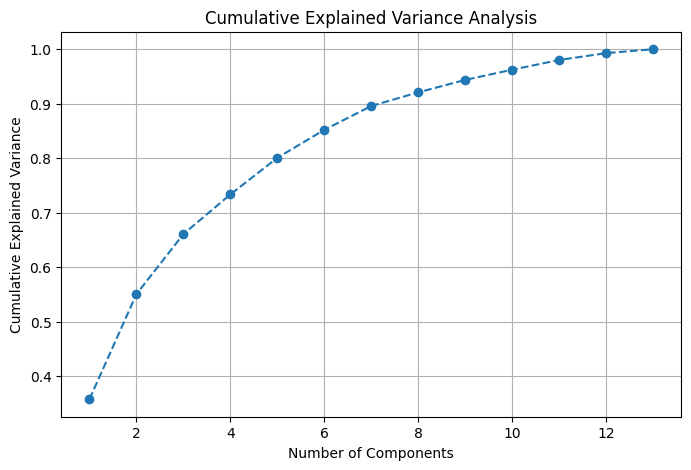

In [11]:
plt.figure(figsize=(8,5))
plt.plot(range(1,len(explained_variance)+1),cumulative_variance,marker='o',linestyle='--')
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Cumulative Explained Variance Analysis")
plt.grid(True)
plt.show()

step 8 : visualise PC1 and PC2

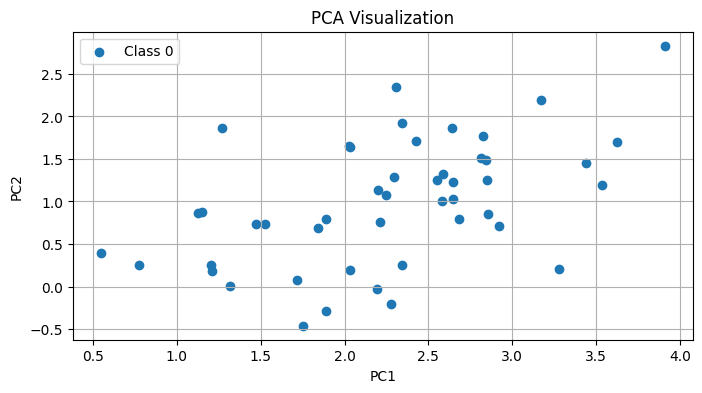

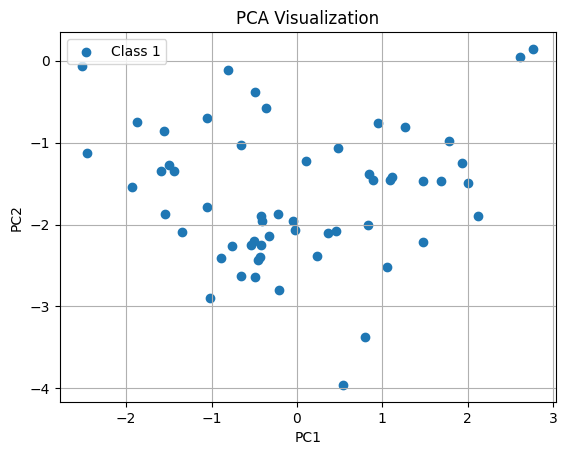

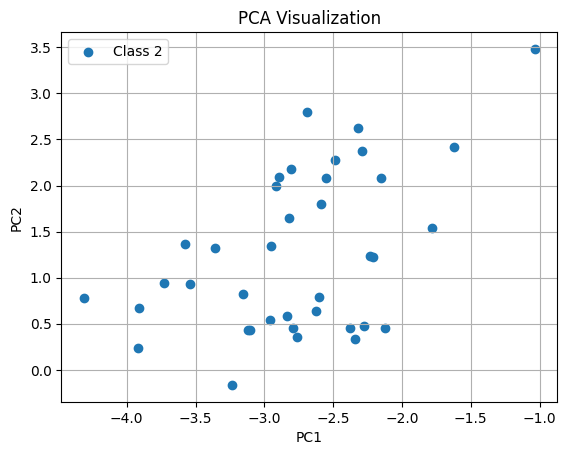

In [17]:
plt.figure(figsize=(8,4))

for class_label in sorted(set(y_train)):
  mask=y_train==class_label
  plt.scatter(
      X_train_pca[mask,0],
      X_train_pca[mask,1],
      label=f"Class {class_label}"
  )
  plt.xlabel("PC1")
  plt.ylabel("PC2")
  plt.title("PCA Visualization")
  plt.legend()
  plt.grid(True)
  plt.show()

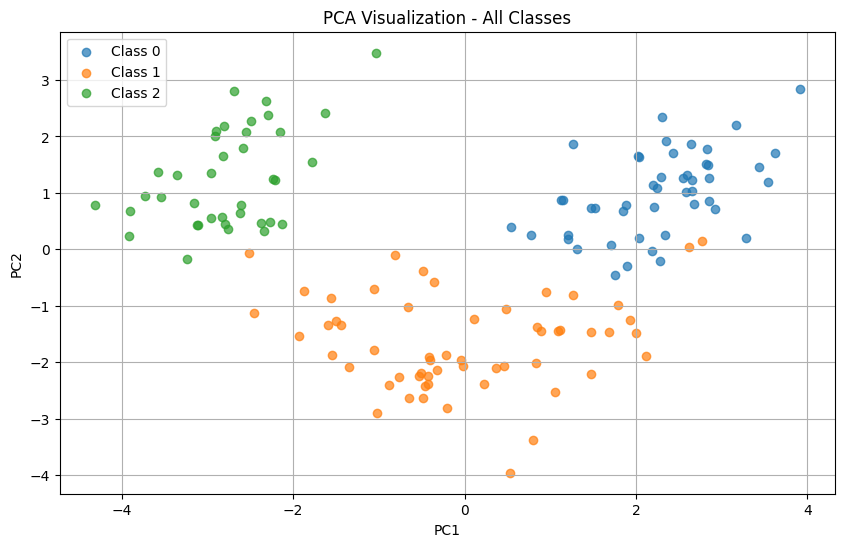

In [22]:

import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for class_label in np.unique(y_train):
    mask = y_train == class_label

    plt.scatter(
        X_train_pca[mask, 0],
        X_train_pca[mask, 1],
        label=f"Class {class_label}",
        alpha=0.7
    )

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Visualization - All Classes")
plt.legend()
plt.grid(True)
plt.show()


step 9: compare classifiaction with and without PCA

In [27]:
from sklearn.tree import DecisionTreeClassifier
model_original=RandomForestClassifier(random_state=42)
model_original.fit(X_train,y_train)
y_pred_original=model_original.predict(X_test)

accuracy_original=accuracy_score(y_test,y_pred_original)
print("Accuracy with Original Features:",accuracy_original)

print("model using pc1 and pc2 components")
model_pca=RandomForestClassifier(n_estimators=100,random_state=42)
model_pca.fit(X_train_pca,y_train)
y_pred_pca=model_pca.predict(X_test_pca)

accuracy_pca=accuracy_score(y_test,y_pred_pca)
print("Accuracy with PCA Features:",accuracy_pca)

Accuracy with Original Features: 1.0
model using pc1 and pc2 components
Accuracy with PCA Features: 0.8888888888888888


PCA is an unsupervised dimensionality reduction technique.

PCA maximizes variance, not classification accuracy.

Therefore:
- Higher explained variance does not guarantee higher accuracy.
- Dimensionality reduction can remove useful information.
- Fewer features may reduce computational cost.
- The best number of components should be selected based on model evaluation.

## Key Interpretation & Final Takeaways

### 1. Explained Variance

- PC1 captures **35.79%** of the total variance.
- PC2 captures **19.27%** of the total variance.
- Together, PC1 and PC2 retain **55.06%** of the original variance.

This means the two-dimensional PCA representation preserves approximately 55.06% of the dataset's variance.

### 2. Class Distribution

The PCA scatter plot reveals different distribution patterns for the three classes:

- **Class 0:** Mostly located in the positive PC1 and PC2 region.
- **Class 1:** Concentrated around negative PC2 values.
- **Class 2:** Mostly distributed along negative PC1 values.

These patterns help visualize how the classes are distributed in the reduced feature space.

### 3. Class Overlap

Some data points overlap in the PC1-PC2 space, making certain classes harder to distinguish.

PCA maximizes variance, not class separation. Therefore, the principal components may not preserve all the information required for classification.

### 4. Original Feature Performance

- Features used: **13**
- Model: Random Forest Classifier
- Test Accuracy: **100%**

The model achieved perfect accuracy on the evaluated test set using all 13 original features.

### 5. Reduced Feature Performance

- Features used: **2 (PC1 and PC2)**
- Model: Random Forest Classifier
- Test Accuracy: **88.89%**

The decrease in performance may be due to the loss of some classification-relevant information during dimensionality reduction.

### 6. Final Conclusion

PCA successfully reduced the dimensionality of the Wine Dataset from 13 features to 2 principal components, enabling two-dimensional visualization.

However, this reduction resulted in an **11.11 percentage-point decrease in classification accuracy**, from 100% to 88.89%.

The key takeaway is that dimensionality reduction involves a trade-off between:

- Reduced feature complexity
- Information retention
- Model performance

**Final Insight:** PCA is useful for dimensionality reduction and visualization, but the number of principal components should be selected by balancing explained variance and predictive performance.